# 05 — Feature engineering and selection

Builds every engineered column via `src/features.py`, verifies the
no-leakage construction of the director history features, then runs three
selection diagnostics — correlation filter, variance inflation factors,
and mutual information against each target — to justify the feature set
Chapter 5 models with. Output: `data/processed/movies_features.parquet`.

**Leakage rules enforced here**
- Director history uses only strictly earlier films, within this dataset.
- `Total_Votes` and `Popularity_Score` are *post-release outcomes*, not
  attributes known before release. They are kept in the frame for
  descriptive use but barred from the Chapter 5 predictor lists.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.feature_selection import mutual_info_classif, mutual_info_regression
from statsmodels.stats.outliers_influence import variance_inflation_factor

from src import features as F
from src.load import PROCESSED, load_interim
from src.plotting import apply_style, save_fig
from src.reporting import fmt_int, write_stats, write_table

apply_style()
pd.set_option("display.max_columns", None)
pd.set_option("display.width", 160)

stats = {}

df = load_interim("movies_clean")
df = F.build_features(df)
new_cols = [c for c in df.columns if c not in load_interim("movies_clean").columns]
print(f"{len(new_cols)} engineered columns:")
print(new_cols)

33 engineered columns:
['roi', 'profit', 'is_profitable', 'release_month', 'release_quarter', 'release_decade', 'is_summer_release', 'is_holiday_release', 'genre_count', 'genre_action', 'genre_adventure', 'genre_animation', 'genre_comedy', 'genre_crime', 'genre_documentary', 'genre_drama', 'genre_family', 'genre_fantasy', 'genre_history', 'genre_horror', 'genre_music', 'genre_mystery', 'genre_romance', 'genre_science_fiction', 'genre_tv_movie', 'genre_thriller', 'genre_war', 'genre_western', 'is_english', 'director_prior_film_count', 'director_mean_prior_rating', 'studio_tier', 'overview_length']


## Spot-check: the extracted financial features

In [2]:
fin = df[df["has_financials"] & ~df["is_future"]].copy()
stats["n_financial"] = len(fin)
stats["pct_profitable"] = round(float(fin["is_profitable"].mean()) * 100, 1)
print(f"financial sample n = {len(fin):,}")
print(f"profitable (revenue > budget): {stats['pct_profitable']}%")
fin[["Title", "Budget", "Worldwide_Revenue", "roi", "profit", "is_profitable"]].head(5)

financial sample n = 6,560
profitable (revenue > budget): 73.4%


,Title,Budget,Worldwide_Revenue,roi,profit,is_profitable
0,Interstellar,165000000.0,7.466067e+08,4.524889,5.816067e+08,True
1,Guardians of the Galaxy,170000000.0,7.727766e+08,4.545745,6.027766e+08,True
2,Harry Potter and the Philosopher's Stone,125000000.0,1.029375e+09,8.234997,9.043746e+08,True
3,The Shawshank Redemption,25000000.0,2.834147e+07,1.133659,3.341469e+06,True
4,Avengers: Infinity War,300000000.0,2.052415e+09,6.841383,1.752415e+09,True


## No-leakage check on director history

For each film, `director_prior_film_count` and
`director_mean_prior_rating` may use only films released **strictly
earlier**. A director's filmography in release order makes the
construction visible: the prior-rating column always lags one film behind.

In [3]:
chk = df[df["Director"] == "Christopher Nolan"].sort_values("Release_Date")[
    ["Title", "Release_Year", "Audience_Rating",
     "director_prior_film_count", "director_mean_prior_rating"]
]
chk.round(3)

,Title,Release_Year,Audience_Rating,director_prior_film_count,director_mean_prior_rating
8011,Doodlebug,1997,6.500,0,NaN
2838,Following,1999,7.100,1,6.500
119,Memento,2000,8.173,2,6.800
931,Insomnia,2002,7.000,3,7.258
41,Batman Begins,2005,7.730,4,7.193
107,The Prestige,2006,8.211,5,7.301
5,The Dark Knight,2008,8.536,6,7.452
32,Inception,2010,8.374,7,7.607
20,The Dark Knight Rises,2012,7.797,8,7.703
0,Interstellar,2014,8.489,9,7.713


In [4]:
# Mechanical verification across the whole dataset: recompute the prior
# mean for a random sample of films the slow way and compare.
rng = np.random.default_rng(0)
sample = df.dropna(subset=["Director", "Release_Date"]).sample(500, random_state=0)
ok = 0
for idx, row in sample.iterrows():
    earlier = df[
        (df["Director"] == row["Director"]) & (df["Release_Date"] < row["Release_Date"])
    ]["Audience_Rating"]
    expect = earlier.mean() if len(earlier) else np.nan
    got = row["director_mean_prior_rating"]
    if (pd.isna(expect) and pd.isna(got)) or (abs(expect - got) < 1e-9):
        ok += 1
print(f"spot-check: {ok}/500 films match an independent recomputation")
assert ok >= 498  # tolerate same-day release ties only
stats["director_check_matched"] = ok
stats["director_check_n"] = 500
stats["n_engineered"] = len(new_cols)

spot-check: 500/500 films match an independent recomputation


## Studio tier

A film takes the tier of its best-connected production company, ranked by
how many films in the cleaned dataset the company appears on:
major >= 100 films, mid >= 20, else indie.

In [5]:
counts = F.company_counts(df)
print("most frequent companies:")
print(counts.head(8).to_string())
tier_counts = df["studio_tier"].value_counts()
stats["studio_tier_major"] = int(tier_counts.get("major", 0))
stats["studio_tier_mid"] = int(tier_counts.get("mid", 0))
stats["studio_tier_indie"] = int(tier_counts.get("indie", 0))
tier_counts

most frequent companies:
Production_Company
Universal Pictures       400
Paramount Pictures       346
Columbia Pictures        305
Warner Bros. Pictures    289
20th Century Fox         189
New Line Cinema          189
Walt Disney Pictures     161
Metro-Goldwyn-Mayer      125


studio_tier
indie      4858
mid        3057
major      2054
unknown      27
Name: count, dtype: int64

In [6]:
# Does the tier mean anything? Median revenue by tier on the financial sample.
fin = df[df["has_financials"] & ~df["is_future"]]
tier_rev = fin.groupby("studio_tier")["Worldwide_Revenue"].agg(
    n="size", median_revenue="median"
).round(0).sort_values("median_revenue", ascending=False)
for t in ["major", "mid", "indie"]:
    stats[f"tier_{t}_median_revenue_m"] = round(float(tier_rev.loc[t, "median_revenue"]) / 1e6, 1)
tier_rev

,n,median_revenue
studio_tier,,
major,1866,83376770.0
mid,2108,46760246.0
indie,2586,16900000.0


## Calendar flags

`is_summer_release` (May–July) and `is_holiday_release` (November–
December) use the conventional industry windows, fixed before looking at
outcomes rather than tuned on them; Chapter 3's month plot already showed
those windows lead.

In [7]:
stats["n_summer"] = int(df["is_summer_release"].sum())
stats["n_holiday"] = int(df["is_holiday_release"].sum())
print(f"summer releases: {stats['n_summer']:,}   holiday releases: {stats['n_holiday']:,}")

summer releases: 2,288   holiday releases: 1,861


## Selection diagnostics

Candidate predictors (all knowable before release):
numeric — deflated budget, runtime, year, genre count, director history,
overview length; binary — language and the two release windows; the
one-hot genre flags; categorical studio tier and content rating enter the
models encoded in Chapter 5. Diagnostics run on the financial sample.

In [8]:
# Diagnostic frame: log-transform the skewed money column, fill the two
# NaN-able numerics with medians PLUS indicator flags (diagnostics only —
# Chapter 5 imputes inside a Pipeline fitted on training folds).
diag = fin.copy()
diag["log_budget_2025"] = np.log1p(diag["Budget_2025usd"].astype("float64"))
diag["log_revenue"] = np.log1p(diag["Worldwide_Revenue"].astype("float64"))
diag["log_roi"] = np.log(diag["roi"].astype("float64"))

num = ["log_budget_2025", "Runtime_Mins", "Release_Year", "genre_count",
       "director_prior_film_count", "director_mean_prior_rating", "overview_length"]
binary = ["is_english", "is_summer_release", "is_holiday_release"]
genre_cols = sorted(c for c in diag.columns if c.startswith("genre_") and c != "genre_count")

X = diag[num + binary + genre_cols].copy()
for c in X.columns:
    X[c] = X[c].astype("float64")
X["debut_director"] = X["director_mean_prior_rating"].isna().astype(float)
for c in ["director_mean_prior_rating", "Runtime_Mins", "overview_length", "log_budget_2025"]:
    X[c] = X[c].fillna(X[c].median())
X = X.dropna()
print(f"diagnostic matrix: {X.shape[0]:,} films x {X.shape[1]} features")

diagnostic matrix: 6,560 films x 30 features


### 1. Correlation filter

Spearman correlations among the numeric predictors and with the three
targets. The filter flags predictor pairs above |r| = 0.8 — none of the
retained set reaches it.

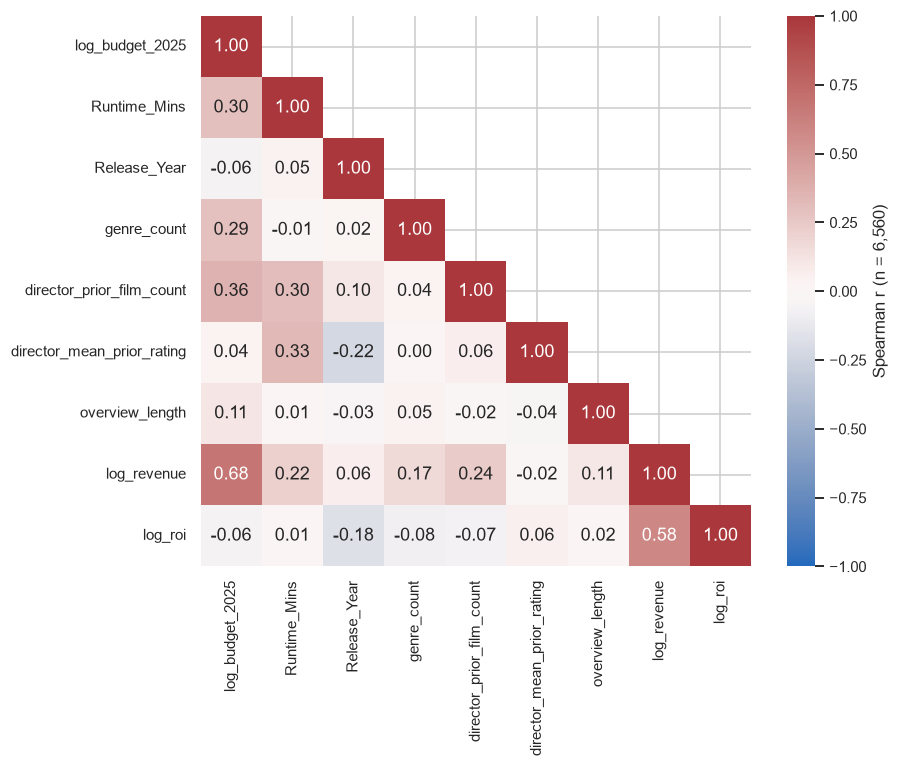

predictor pairs with |Spearman r| > 0.8: 0


In [9]:
corr_cols = num + ["log_revenue", "log_roi"]
cm = diag[corr_cols].astype("float64").corr(method="spearman")

fig, ax = plt.subplots(figsize=(8.5, 6.5))
mask = np.triu(np.ones_like(cm, dtype=bool), k=1)
sns.heatmap(cm, mask=mask, annot=True, fmt=".2f", cmap="vlag", center=0,
            vmin=-1, vmax=1, square=True,
            cbar_kws={"label": f"Spearman r (n = {len(diag):,})"}, ax=ax)
save_fig(fig, "fig4_1_feature_corr")
plt.show()

pairs = cm.where(~np.eye(len(cm), dtype=bool)).abs()
high = pairs[num].loc[num].stack()
high = high[high > 0.8]
stats["collinear_pairs_over_0p8"] = int(len(high) // 2)
print("predictor pairs with |Spearman r| > 0.8:", len(high) // 2)

### 2. Variance inflation factors

VIF on the standardised numeric block (with intercept). The usual worry
threshold is 5.

In [10]:
from sklearn.preprocessing import StandardScaler

vif_X = X[num + ["debut_director"]].copy()
vif_X = pd.DataFrame(StandardScaler().fit_transform(vif_X), columns=vif_X.columns)
vif_X.insert(0, "const", 1.0)
vif = pd.Series(
    [variance_inflation_factor(vif_X.values, i) for i in range(1, vif_X.shape[1])],
    index=vif_X.columns[1:], name="VIF",
).sort_values(ascending=False)
stats["max_vif"] = round(float(vif.drop("debut_director").max()), 2)
# VIF on the numeric block alone cannot see one exact dependency: genre_count
# is the row sum of the one-hot genre flags. Verify it, because it means the
# two cannot both enter a linear model.
flag_sum = diag[genre_cols].astype(int).sum(axis=1)
exact = bool((flag_sum == diag["genre_count"].astype(int)).all())
stats["genre_count_equals_flag_sum"] = "yes" if exact else "no"
assert exact
print("genre_count == sum of one-hot genre flags for every film:", exact)

vif_tex = vif.reset_index()
vif_tex.columns = ["feature", "VIF"]
vif_tex["VIF"] = vif_tex["VIF"].map(lambda v: f"{v:.2f}")
write_table(vif_tex, "tab4_1_vif")
vif.round(2)

genre_count == sum of one-hot genre flags for every film: True


debut_director                1.41
log_budget_2025               1.33
director_prior_film_count     1.32
Runtime_Mins                  1.24
director_mean_prior_rating    1.15
genre_count                   1.10
Release_Year                  1.07
overview_length               1.02
Name: VIF, dtype: float64

`director_mean_prior_rating` and `debut_director` are mechanically
coupled (the indicator marks exactly the rows whose rating was filled),
which inflates that pair; among the real predictors no VIF approaches 5,
so the numeric block carries no harmful collinearity.

**But the numeric-block VIF misses one exact dependency**, verified
above: `genre_count` is the row sum of the one-hot genre flags. A first
draft of the Chapter 5 OLS included both, and its genre coefficients came
out unidentified (shifting by ~3 between runs). `genre_count` is
therefore dropped from every model; the flags are kept.

### 3. Mutual information against each target

Nonparametric dependence of every candidate feature on each of the three
Chapter 5 targets. `Total_Votes` is added **only** to demonstrate the
leakage it would cause — it is barred from the models.

In [11]:
Xmi = X.copy()
Xmi["Total_Votes_LEAKY"] = diag.loc[X.index, "Total_Votes"].astype("float64")
discrete = np.array([c in binary + genre_cols for c in Xmi.columns])

y_rev = diag.loc[X.index, "log_revenue"]
y_roi = diag.loc[X.index, "log_roi"]
y_prof = diag.loc[X.index, "is_profitable"].astype(bool)

mi = pd.DataFrame(
    {
        "log1p(revenue)": mutual_info_regression(Xmi, y_rev, discrete_features=discrete, random_state=0),
        "log(ROI)": mutual_info_regression(Xmi, y_roi, discrete_features=discrete, random_state=0),
        "is_profitable": mutual_info_classif(Xmi, y_prof, discrete_features=discrete, random_state=0),
    },
    index=Xmi.columns,
)
mi_sorted = mi.sort_values("log1p(revenue)", ascending=False)
stats["mi_top_revenue_feature"] = str(mi.drop(index="Total_Votes_LEAKY")["log1p(revenue)"].idxmax())
stats["mi_budget_revenue"] = round(float(mi.loc["log_budget_2025", "log1p(revenue)"]), 3)
stats["mi_budget_roi"] = round(float(mi.loc["log_budget_2025", "log(ROI)"]), 3)
stats["mi_votes_revenue_leaky"] = round(float(mi.loc["Total_Votes_LEAKY", "log1p(revenue)"]), 3)
stats["mi_votes_roi_leaky"] = round(float(mi.loc["Total_Votes_LEAKY", "log(ROI)"]), 3)
stats["mi_votes_profitable_leaky"] = round(float(mi.loc["Total_Votes_LEAKY", "is_profitable"]), 3)
best_legit_prof = mi.drop(index="Total_Votes_LEAKY")["is_profitable"].max()
stats["mi_best_legit_profitable"] = round(float(best_legit_prof), 3)
stats["mi_leak_ratio_profitable"] = round(float(mi.loc["Total_Votes_LEAKY", "is_profitable"] / best_legit_prof), 1)
stats["mi_roi_to_revenue_ratio_budget"] = round(
    float(mi.loc["log_budget_2025", "log(ROI)"] / mi.loc["log_budget_2025", "log1p(revenue)"]), 2)

mi_tex = mi_sorted.head(12).reset_index(names="feature")
for c in ["log1p(revenue)", "log(ROI)", "is_profitable"]:
    mi_tex[c] = mi_tex[c].map(lambda v: f"{v:.3f}")
mi_tex["feature"] = mi_tex["feature"].str.replace("_LEAKY", " (barred)", regex=False)
write_table(mi_tex, "tab4_2_mutual_info")
mi_sorted.round(3).head(12)

,log1p(revenue),log(ROI),is_profitable
Total_Votes_LEAKY,0.357,0.107,0.080
log_budget_2025,0.347,0.068,0.009
Release_Year,0.062,0.043,0.003
genre_adventure,0.052,0.001,0.001
director_mean_prior_rating,0.047,0.026,0.007
genre_action,0.028,0.000,0.000
genre_family,0.028,0.006,0.004
is_english,0.028,0.000,0.001
genre_count,0.027,0.009,0.000
genre_drama,0.026,0.008,0.004


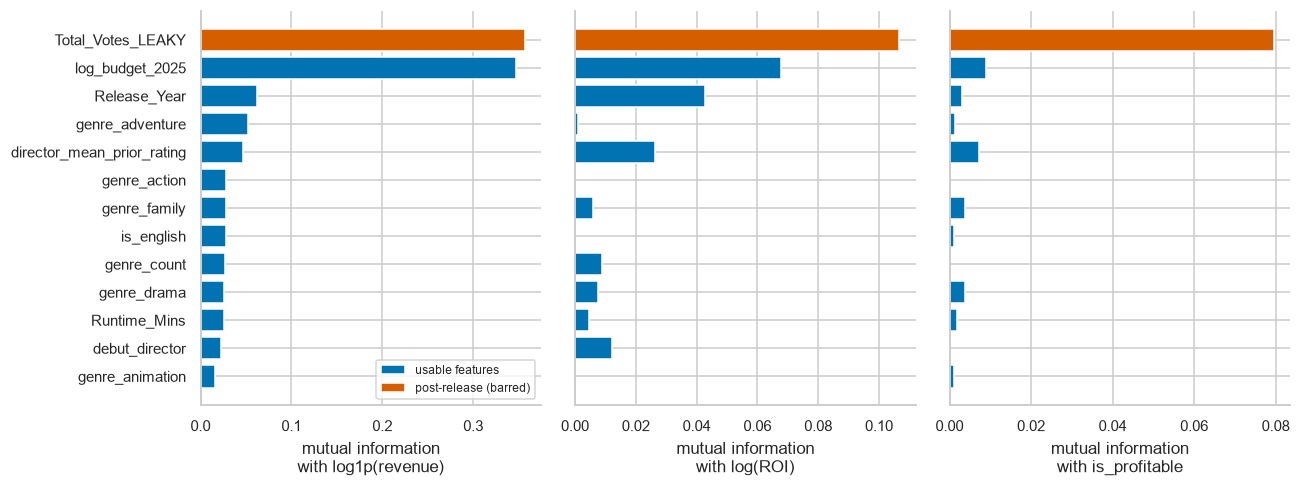

In [12]:
top = mi_sorted.drop(index="Total_Votes_LEAKY").head(12).iloc[::-1]
leak = mi_sorted.loc[["Total_Votes_LEAKY"]]

fig, axes = plt.subplots(1, 3, figsize=(12, 4.6), sharey=True)
for ax, col in zip(axes, mi.columns):
    ax.barh(top.index, top[col], color="C0", label="usable features")
    ax.barh(leak.index, leak[col], color="C3", label="post-release (barred)")
    ax.set_xlabel(f"mutual information\nwith {col}")
axes[0].legend(loc="lower right", fontsize=8)
fig.tight_layout()
save_fig(fig, "fig4_2_mutual_info")
plt.show()

### Selection decisions

- **Kept**: deflated log budget, runtime, one-hot genres, language, the
  two release-window flags, director history pair, studio tier, content
  rating, overview length. No pair exceeds the correlation filter and no
  real VIF approaches 5. Release year is kept for description but not
  used as a predictor under the year-based split (Chapter 5 explains).
- **Dropped as an exact linear combination**: `genre_count` (= sum of
  the genre flags).
- **Barred as leakage**: `Total_Votes` and `Popularity_Score`. The red
  bar makes the case per target: on revenue, votes match the single best
  legitimate feature (0.357 vs budget's 0.347); on log(ROI) they carry
  ~1.6x the information of budget; and on `is_profitable` they carry
  roughly nine times the information of any legitimate feature — a
  signal that only exists because profitable films go on to collect
  votes. That is what post-release data does, and why it is barred.
- **Dropped as redundant**: `release_decade` and `release_quarter`
  duplicate year and month at coarser resolution; `profit` is a target
  transform, not a feature.
- The MI panels already preview Chapter 5's headline: every feature's
  information about **log(ROI)** is a fraction of its information about
  revenue — ROI is the harder target.

In [13]:
PROCESSED.mkdir(parents=True, exist_ok=True)
df.to_parquet(PROCESSED / "movies_features.parquet")
out = write_stats("ch04_features", stats)
print(f"wrote {PROCESSED / 'movies_features.parquet'}")
print(f"{len(stats)} statistics -> {out.relative_to(ROOT)}")
stats

wrote C:\EDA_Project\movie-success-eda\data\processed\movies_features.parquet
25 statistics -> report\stats\ch04_features.json


{'n_financial': 6560,
 'pct_profitable': 73.4,
 'director_check_matched': 500,
 'director_check_n': 500,
 'n_engineered': 33,
 'studio_tier_major': 2054,
 'studio_tier_mid': 3057,
 'studio_tier_indie': 4858,
 'tier_major_median_revenue_m': 83.4,
 'tier_mid_median_revenue_m': 46.8,
 'tier_indie_median_revenue_m': 16.9,
 'n_summer': 2288,
 'n_holiday': 1861,
 'collinear_pairs_over_0p8': 0,
 'max_vif': 1.33,
 'genre_count_equals_flag_sum': 'yes',
 'mi_top_revenue_feature': 'log_budget_2025',
 'mi_budget_revenue': 0.347,
 'mi_budget_roi': 0.068,
 'mi_votes_revenue_leaky': 0.357,
 'mi_votes_roi_leaky': 0.107,
 'mi_votes_profitable_leaky': 0.08,
 'mi_best_legit_profitable': 0.009,
 'mi_leak_ratio_profitable': 8.8,
 'mi_roi_to_revenue_ratio_budget': 0.2}